Correlation Heatmap
A correlation heatmap helps us understand how numerical columns in your dataset are related to one another.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
df=pd.read_csv("/home/student/Downloads/ds-ev-range-analysis/data/EV_Cleaned_2025.csv")

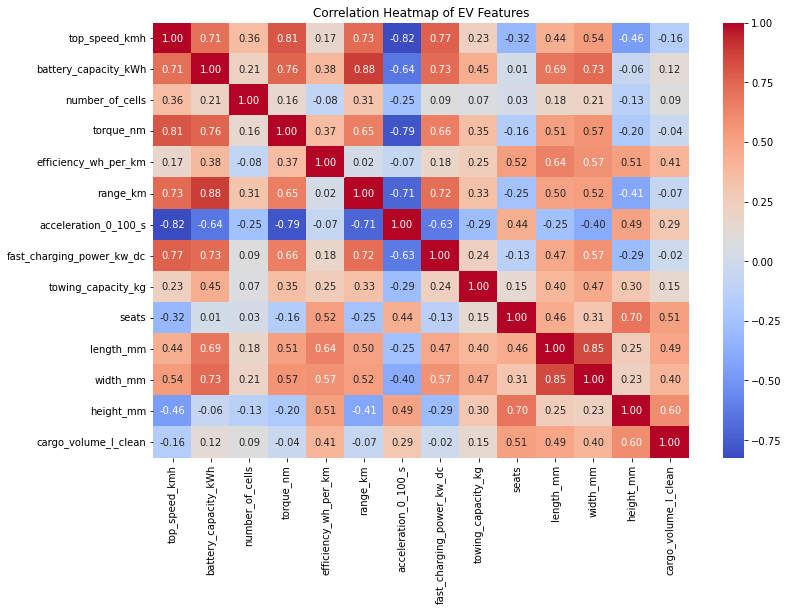

In [4]:
plt.figure(figsize=(12, 8))
correlation = df.select_dtypes(include="number").corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap of EV Features")
plt.show()

Identify Outliers in the Dataset
Outliers are values that are unusually high or low compared with most other values in a dataset.
For example, if most EVs have a driving range between 200 and 700 km, but one vehicle has a range of 1,500 km, that value may need investigation.

They help identify unusual observations.
They may reveal incorrect data.
They can affect Linear Regression predictions

Create a box plot for EV range

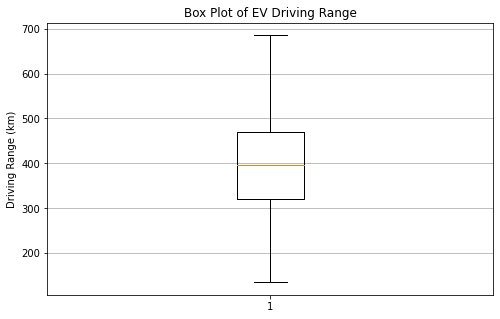

In [5]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["range_km"])
plt.ylabel("Driving Range (km)")
plt.title("Box Plot of EV Driving Range")
plt.grid(axis="y")
plt.show()

box plots for battery capacity and efficiency.

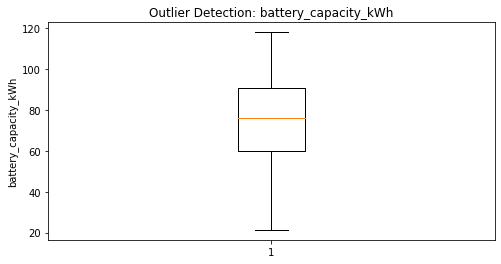

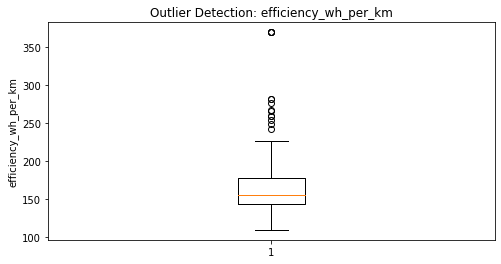

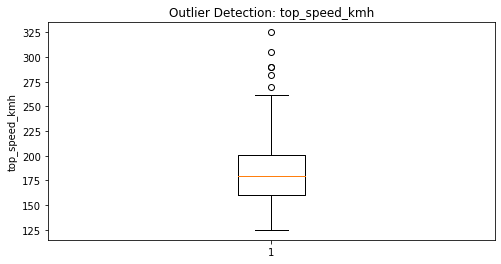

In [6]:
columns = ["battery_capacity_kWh","efficiency_wh_per_km","top_speed_kmh"]
for column in columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column])
    plt.title("Outlier Detection: " + column)
    plt.ylabel(column)
    plt.show()

Calculate Outliers Using IQR
What is IQR?
IQR measures the spread of the middle 50% of the dataset.
We calculate:
Q1 = 25th percentile
Q3 = 75th percentile
IQR = Q3 − Q1
We identify potential outliers using these limits:
Lower limit = Q1 − 1.5 × IQR
Upper limit = Q3 + 1.5 × IQR

In [7]:
Q1 = df["range_km"].quantile(0.25)
Q3 = df["range_km"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 320.0
Q3: 470.0
IQR: 150.0
Lower Limit: 95.0
Upper Limit: 695.0


Identifying potential outliers

In [8]:
outliers = df[(df["range_km"] < lower_limit)|(df["range_km"] > upper_limit)]
print("Number of potential outliers:", len(outliers))

Number of potential outliers: 0


Feature Selection and Preparation
Before building Linear Regression, we need to decide which columns the model should use.
Understand Features and Target
In Machine Learning:
Features (X): Input columns used to make predictions.
Target (y): The value we want the model to predict.
For my project:
Target variable:
range_km
We want to predict the driving range of an electric vehicle.
Possible input features:
1. battery_capacity_kWh
2. efficiency_wh_per_km
3. top_speed_kmh
4. acceleration_0_100_s
5. seats
6. torque_nm
We will evaluate these features before finalizing the model.

Create X and y

In [10]:
features = ["battery_capacity_kWh","efficiency_wh_per_km","top_speed_kmh","acceleration_0_100_s","seats","torque_nm"]
x = df[features]
y = df["range_km"]

We are not including range_km inside X because that would give the model the answer it is supposed to predict. This is called target leakage.

In [12]:
print("Input Features:")
print(x.head())
print("\nTarget Values:")
print(y.head())
print("\nInput Shape:", x.shape)
print("Target Shape:", y.shape)

Input Features:
   battery_capacity_kWh  efficiency_wh_per_km  top_speed_kmh  \
0                  37.8                   156            155   
1                  37.8                   149            155   
2                  50.8                   158            200   
3                  50.8                   158            200   
4                  60.0                   156            150   

   acceleration_0_100_s  seats  torque_nm  
0                   7.0      4      235.0  
1                   7.0      4      235.0  
2                   5.9      5      345.0  
3                   6.2      5      345.0  
4                   7.5      5      310.0  

Target Values:
0    225
1    225
2    280
3    280
4    315
Name: range_km, dtype: int64

Input Shape: (478, 6)
Target Shape: (478,)


Check Missing Values in Selected Features
Before training a model, we must check whether our input features contain missing values.

In [ ]:
print("Missing values in X:")
print(x.isnull().sum())
print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               7
dtype: int64

Missing values in y:
0


Handle Missing Values
We will use Median Imputation for numerical features.
Median means the middle value when all values are arranged in ascending order

In [2]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(x)
print("Missing values handled successfully!")
print("New input shape:", X_imputed.shape)

NameError: name 'x' is not defined